In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx

## Setup Paths

In [2]:

ROOT = Path.cwd().parent
RAW_DIR = ROOT / "data/raw"
PROCESSED_DIR = ROOT / "data/processed"

## Create a bounding box for New Zealand (Exclude Chathams Islands)

In [3]:
from shapely.geometry import box
NZ_BBOX = (166.0, -47.5, 179.0, -34.0)
bbox_nz = gpd.GeoDataFrame(geometry=[box(*NZ_BBOX)], crs="EPSG:4326")

## Load Excel files

In [4]:
WATER_QUALITY_FILES = (
    "LAWA River Water Quality Monitoring Data_South Island 1of2_10Feb2026.xlsx",
    "LAWA River Water Quality Monitoring Data_South Island 2of2_10Feb2026.xlsx",
    "LAWA River Water Quality Monitoring Data_North Island 1of3_16Dec2025.xlsx",
    "LAWA River Water Quality Monitoring Data_North Island 2of3_9Feb2026.xlsx",
    "LAWA River Water Quality Monitoring Data_North Island 3of3_9Feb2026.xlsx"
)

# SHEET = "MonitoringData (2004-24)_SI1"
df_list = [ pd.read_excel(RAW_DIR / f, sheet_name=1) 
            for f in WATER_QUALITY_FILES
]

## Standardize Column Names for GeoDataFrame

In [5]:
# Check if all dfs have the same number of columns
col_counts = [len(c.columns) for c in df_list]
print(f'number of columns: {col_counts}')
# check if all column names are the same
col0 = df_list[0].columns.to_list()
col0 = [c.strip() for c in col0]
def col_check(cols):
    for a, b in zip(col0, cols):
        if a.casefold() != b.strip().casefold():
            print(f'a={a}, b={b}')
            return False
    return True
    
res = True
for df in df_list[1:]:
    res = res and col_check(df.columns.to_list()) 
print(f'All columns are the same: {res}')


number of columns: [20, 20, 20, 20, 20]
a=QCNumber (Agency value), b=QCNumber
All columns are the same: False


In [6]:
# Note one file has "QCNumber" instead of "QCNumber (Agency value)"
rename_map = {a.casefold():a for a in col0}
rename_map["QCNumber".casefold()] = "QCNumber"
rename_map["QCNumber (Agency value)".casefold()] = "QCNumber"
rename_map


{'region': 'Region',
 'agency': 'Agency',
 'catchment': 'Catchment',
 'lawasiteid': 'LawaSiteID',
 'siteid': 'SiteID',
 'councilsiteid': 'CouncilSiteID',
 'latitude': 'Latitude',
 'longitude': 'Longitude',
 'wfslanduse': 'WFSLanduse',
 'wfsaltitude': 'WFSAltitude',
 'reclandcover': 'RECLandCover',
 'indicator': 'Indicator',
 'sampledatetime': 'SampleDateTime',
 'timezone': 'Timezone',
 'agencyrawvalue': 'AgencyRawValue',
 'symbol': 'Symbol',
 'value': 'Value',
 'units': 'Units',
 'qcnumber (agency value)': 'QCNumber',
 'qcnemsequivalent': 'QCNEMSEquivalent',
 'qcnumber': 'QCNumber'}

In [7]:
for df in df_list:
    cols = df.columns.to_list()
    cols = [rename_map[c.strip().casefold()] for c in cols]
    df.columns = cols

In [8]:
df = pd.concat(df_list, ignore_index=True)

gdf_water_qual = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["Longitude"], df["Latitude"]),
    crs="EPSG:4326"
) 

## Check the datatype for each column

In [9]:
for col in gdf_water_qual.select_dtypes(include="object").columns:
    types = gdf_water_qual[col].dropna().map(type).unique()
    if len(types) > 1:
        print(col, types)
        

/tmp/ipykernel_28030/3653686465.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in gdf_water_qual.select_dtypes(include="object").columns:


Catchment [<class 'int'> <class 'str'>]
SiteID [<class 'str'> <class 'int'>]
CouncilSiteID [<class 'str'> <class 'int'>]
AgencyRawValue [<class 'str'> <class 'float'> <class 'int'>]


AgencyRawValues are supposed to be all numeric, but some have "<" ">" to indicate detection limits

In [10]:

s = gdf_water_qual["AgencyRawValue"].dropna()
t = s.map(type)

print(t.value_counts())          # how many of each type
for typ in t.unique():
    print(typ, s[t == typ].unique()[:5])


mask = gdf_water_qual["AgencyRawValue"] == ">1.5"

gdf_water_qual.loc[mask, ["AgencyRawValue", "Symbol", "Value", "Indicator", "Units"]]

AgencyRawValue
<class 'float'>    1508627
<class 'int'>       220566
<class 'str'>       113579
Name: count, dtype: int64
<class 'str'> ['<0.005' '<0.01' '>1.5' '>3.32' '<0.012']
<class 'float'> [0.017 0.014 5.45 0.68 5.85]
<class 'int'> [7 8 10 3 22]


,AgencyRawValue,Symbol,Value,Indicator,Units
58,>1.5,>,1.5,Clarity (BDISC),m
2027,>1.5,>,1.5,Clarity (BDISC),m
2030,>1.5,>,1.5,Clarity (BDISC),m
2033,>1.5,>,1.5,Clarity (BDISC),m
3598,>1.5,>,1.5,Clarity (BDISC),m
...,...,...,...,...,...
1437495,>1.5,>,1.5,Clarity (BDISC),m
1451124,>1.5,>,1.5,Clarity (BDISC),m
1451150,>1.5,>,1.5,Clarity (BDISC),m
1453417,>1.5,>,1.5,Clarity (BDISC),m


Since value provides the numeric value, keep AgencyRawValue as string.

In [11]:
gdf_water_qual["AgencyRawValue"] = gdf_water_qual["AgencyRawValue"].astype("string")

##  Also check other columns with mixed datatype

In [12]:
s = gdf_water_qual["SiteID"].dropna()
t = s.map(type)

print(t.value_counts())          # how many of each type
for typ in t.unique():
    print(typ, s[t == typ].unique()[:5])

SiteID
<class 'str'>    1637876
<class 'int'>     213081
Name: count, dtype: int64
<class 'str'> ['Clarence River over Jacks Pass' 'Clarence River above river mouth'
 'Blue Duck Creek Above SH1' 'Hapuku River at SH1' 'Lyell Creek u/s SH1']
<class 'int'> [1201 5597 176 182 48]


In [13]:
s = gdf_water_qual["Catchment"].dropna()
t = s.map(type)

print(t.value_counts())          # how many of each type
for typ in t.unique():
    print(typ, s[t == typ].unique()[:5])

Catchment
<class 'str'>    1656190
<class 'int'>     194767
Name: count, dtype: int64
<class 'int'> [6210000 6280000 6290000 6300000 6310000]
<class 'str'> ['Hurunui River' 'Opihi River' 'Timaru' 'Upper and Lower Waitaki'
 'Waimakariri River']


In [14]:
s = gdf_water_qual["CouncilSiteID"].dropna()
t = s.map(type)

print(t.value_counts())          # how many of each type
for typ in t.unique():
    print(typ, s[t == typ].unique()[:5])

CouncilSiteID
<class 'str'>    1483139
<class 'int'>     367818
Name: count, dtype: int64
<class 'str'> ['sq35818' 'sq35800' 'sq35173' 'sq35174' 'sq33273']
<class 'int'> [8019 44603 45415 45313 45373]


For these, I will keep them as string

In [15]:
gdf_water_qual["Catchment"] = (
    gdf_water_qual["Catchment"].astype("string").str.strip()
)

gdf_water_qual["SiteID"] = gdf_water_qual["SiteID"].astype("string")
gdf_water_qual["CouncilSiteID"] = gdf_water_qual["CouncilSiteID"].astype("string")
# gdf_water_qual["Value"] = pd.to_numeric(gdf_water_qual["Value"], errors="coerce")

## Examine Duplicates

In [16]:
key = ["LawaSiteID", "Indicator", "SampleDateTime"]

dup_key = gdf_water_qual.duplicated(subset=key, keep=False)
print(dup_key.sum())

# exact copies of the whole row (ignoring geometry, which can't be hashed directly)
cols = [c for c in gdf_water_qual.columns if c != "geometry"]
dup_full = gdf_water_qual.duplicated(subset=cols, keep=False)
print(dup_full.sum())

30632
0


In [17]:
key2 = ["LawaSiteID", "Indicator", "SampleDateTime", "Units"]
print(gdf_water_qual.duplicated(subset=key2, keep=False).sum())
gdf_water_qual[gdf_water_qual.duplicated(subset=key2, keep=False)]

44


,Region,Agency,Catchment,LawaSiteID,SiteID,CouncilSiteID,Latitude,Longitude,WFSLanduse,WFSAltitude,...,Indicator,SampleDateTime,Timezone,AgencyRawValue,Symbol,Value,Units,QCNumber,QCNEMSEquivalent,geometry
678108,west coast,West Coast Regional Council,Bradshaws Creek,wcrc-00016,Bradshaws Ck @ Bradshaw Rd,bradshaws ck @ bradshaw rd,-41.760236,171.545017,Rural,Lowland,...,Clarity (BDISC),2011-08-22 13:45:00,NZST,1.04,NaN,1.04,m,NaN,NaN,POINT (171.54502 -41.76024)
678109,west coast,West Coast Regional Council,Bradshaws Creek,wcrc-00016,Bradshaws Ck @ Bradshaw Rd,bradshaws ck @ bradshaw rd,-41.760236,171.545017,Rural,Lowland,...,Clarity (BDISC),2011-08-22 13:45:00,NZST,0.85,NaN,0.85,m,NaN,NaN,POINT (171.54502 -41.76024)
740871,auckland,Auckland Council,Mangawheau,lawa-102372,Mangawhaeu @ Aldridge Rd,108512,-37.105600,175.068250,Rural,Lowland,...,pH,2020-07-07 12:44:00,NZST,6.9,NaN,6.90,ph,NaN,NaN,POINT (175.06825 -37.1056)
740872,auckland,Auckland Council,Mangawheau,lawa-102372,Mangawhaeu @ Aldridge Rd,108512,-37.105600,175.068250,Rural,Lowland,...,pH,2020-07-07 12:44:00,NZST,7.3,NaN,7.30,ph,NaN,NaN,POINT (175.06825 -37.1056)
740873,auckland,Auckland Council,Mangawheau,lawa-102372,Mangawhaeu @ Aldridge Rd,108512,-37.105600,175.068250,Rural,Lowland,...,pH,2020-08-10 13:40:00,NZST,7.1,NaN,7.10,ph,NaN,NaN,POINT (175.06825 -37.1056)
740874,auckland,Auckland Council,Mangawheau,lawa-102372,Mangawhaeu @ Aldridge Rd,108512,-37.105600,175.068250,Rural,Lowland,...,pH,2020-08-10 13:40:00,NZST,7.2,NaN,7.20,ph,NaN,NaN,POINT (175.06825 -37.1056)
740875,auckland,Auckland Council,Mangawheau,lawa-102372,Mangawhaeu @ Aldridge Rd,108512,-37.105600,175.068250,Rural,Lowland,...,pH,2020-09-08 12:05:00,NZST,7.1,NaN,7.10,ph,NaN,NaN,POINT (175.06825 -37.1056)
740876,auckland,Auckland Council,Mangawheau,lawa-102372,Mangawhaeu @ Aldridge Rd,108512,-37.105600,175.068250,Rural,Lowland,...,pH,2020-09-08 12:05:00,NZST,7.32,NaN,7.32,ph,NaN,NaN,POINT (175.06825 -37.1056)
740877,auckland,Auckland Council,Mangawheau,lawa-102372,Mangawhaeu @ Aldridge Rd,108512,-37.105600,175.068250,Rural,Lowland,...,pH,2020-10-07 10:59:00,NZST,7.48,NaN,7.48,ph,NaN,NaN,POINT (175.06825 -37.1056)
740878,auckland,Auckland Council,Mangawheau,lawa-102372,Mangawhaeu @ Aldridge Rd,108512,-37.105600,175.068250,Rural,Lowland,...,pH,2020-10-07 10:59:00,NZST,7.4,NaN,7.40,ph,NaN,NaN,POINT (175.06825 -37.1056)


In [18]:
d = gdf_water_qual[dup_key]
other_cols = [c for c in gdf_water_qual.columns if c not in key + ["geometry"]]

varies = (d.groupby(key)[other_cols]
            .nunique(dropna=False)
            .gt(1)
            .sum()
            .sort_values(ascending=False))
print(varies[varies > 0])

Units               15294
Value               15128
AgencyRawValue      15128
QCNEMSEquivalent      506
QCNumber              506
Symbol                 12
dtype: int64


NTU and FTU are two different methods of measuring turbidity.  NTU (Nephelometric Turbidity Units) is usually tied to US EPA-style methods using a white (broad-spectrum) light.  FTU (Formazin Nephelometric Units) follows the ISO 7027 method which uses near-infrared light source, which is less affected by the water's color.  FNU reading tends to be more reliable. Both are calibriated using formazin.

In [19]:
(d.sort_values(key)
   [key + ["Value", "AgencyRawValue", "Units", "QCNumber", "SiteID", "Agency"]]
   .head(20))

,LawaSiteID,Indicator,SampleDateTime,Value,AgencyRawValue,Units,QCNumber,SiteID,Agency
613773,es-00001,Turbidity,2022-06-16 12:35:00,11.20,11.2,ntu,200.0,Waiau River at Tuatapere,Environment Southland
613774,es-00001,Turbidity,2022-06-16 12:35:00,12.80,12.8,fnu,NaN,Waiau River at Tuatapere,Environment Southland
613775,es-00001,Turbidity,2022-07-14 11:59:00,57.00,57,ntu,200.0,Waiau River at Tuatapere,Environment Southland
613776,es-00001,Turbidity,2022-07-14 11:59:00,74.00,74,fnu,NaN,Waiau River at Tuatapere,Environment Southland
613777,es-00001,Turbidity,2022-08-11 13:04:00,10.30,10.3,ntu,200.0,Waiau River at Tuatapere,Environment Southland
613778,es-00001,Turbidity,2022-08-11 13:04:00,10.50,10.5,fnu,NaN,Waiau River at Tuatapere,Environment Southland
613779,es-00001,Turbidity,2022-09-08 12:39:00,8.00,8,ntu,200.0,Waiau River at Tuatapere,Environment Southland
613780,es-00001,Turbidity,2022-09-08 12:39:00,9.70,9.7,fnu,NaN,Waiau River at Tuatapere,Environment Southland
613781,es-00001,Turbidity,2022-10-13 12:50:00,0.52,0.52,ntu,200.0,Waiau River at Tuatapere,Environment Southland
613782,es-00001,Turbidity,2022-10-13 12:50:00,1.00,1,fnu,NaN,Waiau River at Tuatapere,Environment Southland


Most indicators have only one units.  Some have units that are unspecified.  E. coli and Turbidity requires some investigation.

In [20]:
indicators = list(gdf_water_qual.Indicator.unique())
units = {}
for i in indicators:
    i_filter = (gdf_water_qual.Indicator == i)
    units[i] = list(gdf_water_qual[i_filter].Units.unique())
units

{'Ammoniacal nitrogen': ['mg/l'],
 'Clarity (BDISC)': ['m'],
 'Dissolved inorganic nitrogen': ['mg/l'],
 'Dissolved reactive phosphorus': ['mg/l'],
 'E.coli': ['/100ml', 'ph'],
 'pH': ['unspecified', 'ph', 's.u.'],
 'Total nitrogen': ['mg/l', 'unspecified'],
 'Total oxidised nitrogen': ['mg/l', 'unspecified'],
 'Total phosphorus': ['mg/l'],
 'Turbidity': ['ntu', 'fnu', 'unspecified', 'ph'],
 'Nitrate nitrogen': ['mg/l']}

Are there any NaN?

In [21]:
# one column
print(f'Number of NaN values {gdf_water_qual["Value"].isna().sum()}')


gdf_water_qual[gdf_water_qual["Value"].isna()].head()

Number of NaN values 8185


,Region,Agency,Catchment,LawaSiteID,SiteID,CouncilSiteID,Latitude,Longitude,WFSLanduse,WFSAltitude,...,Indicator,SampleDateTime,Timezone,AgencyRawValue,Symbol,Value,Units,QCNumber,QCNEMSEquivalent,geometry
199192,canterbury,NIWA,Hurunui River,nrwqn-00009,Hurunui at Mandamus,ch1,-42.79112,172.5439,Forest,Upland,...,Ammoniacal nitrogen,2019-09-18 09:15:00,NaN,<NA>,NaN,NaN,mg/l,NaN,NaN,POINT (172.5439 -42.79112)
199193,canterbury,NIWA,Hurunui River,nrwqn-00009,Hurunui at Mandamus,ch1,-42.79112,172.5439,Forest,Upland,...,Ammoniacal nitrogen,2019-10-16 08:30:00,NaN,<NA>,NaN,NaN,mg/l,NaN,NaN,POINT (172.5439 -42.79112)
199194,canterbury,NIWA,Hurunui River,nrwqn-00009,Hurunui at Mandamus,ch1,-42.79112,172.5439,Forest,Upland,...,Ammoniacal nitrogen,2019-11-13 08:10:00,NaN,<NA>,NaN,NaN,mg/l,NaN,NaN,POINT (172.5439 -42.79112)
199446,canterbury,NIWA,Hurunui River,nrwqn-00009,Hurunui at Mandamus,ch1,-42.79112,172.5439,Forest,Upland,...,Clarity (BDISC),2021-02-10 09:20:00,NaN,<NA>,NaN,NaN,m,NaN,NaN,POINT (172.5439 -42.79112)
199449,canterbury,NIWA,Hurunui River,nrwqn-00009,Hurunui at Mandamus,ch1,-42.79112,172.5439,Forest,Upland,...,Clarity (BDISC),2021-05-12 10:25:00,NaN,<NA>,NaN,NaN,m,NaN,NaN,POINT (172.5439 -42.79112)


In [22]:
n_before = len(gdf_water_qual)
gdf_water_qual = gdf_water_qual[gdf_water_qual["Value"].notna()]
print(f"dropped {n_before - len(gdf_water_qual):,} rows with no Value")

dropped 8,185 rows with no Value


Time Range is 20+ years.  This is a goldmine.

In [23]:
gdf_water_qual['SampleDateTime'].describe()

count                       1842772
mean     2016-07-31 08:30:08.728258
min             2004-01-04 21:15:00
25%             2012-06-06 09:13:00
50%             2017-05-08 10:05:00
75%             2021-04-29 14:39:00
max             2025-03-20 10:47:00
Name: SampleDateTime, dtype: object

In [24]:
gdf_water_qual['SampleDateTime'].isna().sum()

np.int64(0)

In [25]:
gdf_water_qual['Timezone'].unique()

<ArrowStringArray>
['NZST', 'UTC - derived', nan, 'NZST - derived']
Length: 4, dtype: str

What are QC Number.

In [26]:
gdf_water_qual['QCNumber'].unique()

array([        nan,  6.0000e+02,  4.0000e+02,  3.0000e+02,  5.0000e+02,
        2.0000e+02,  4.5000e+02,  1.6393e+04,  0.0000e+00,  1.6384e+04,
        4.1000e+01,  5.4300e+02,  6.1000e+02,  4.6000e+02,  3.9000e+01,
        6.1000e+01,  2.5000e+01,  9.0000e+00,  3.5000e+01,  2.1000e+01,
        1.6409e+04,  1.6425e+04,  2.6000e+01,  3.6000e+01,  1.6405e+04,
        1.6423e+04,  5.1000e+01,  6.0000e+01,  5.0000e+01,  1.0000e+02,
        2.2200e+02,  4.0000e+01,  2.1000e+02,  2.3100e+02,  2.2500e+02,
        9.0000e+01,  7.0000e+01, -1.0000e+00,  2.2800e+02,  2.1900e+02])

In [27]:
sites = list(gdf_water_qual['SiteID'].unique())
two_coord_sites = []
for site in sites:
    coords = list(gdf_water_qual[gdf_water_qual.SiteID == site]['geometry'].unique())
    n_coord = len(coords)
    if n_coord > 1:
        print(f'{site} has {n_coord} coordinates')
        pts = gpd.GeoSeries([coords[0], coords[1]], crs="EPSG:4326").to_crs(2193)
        dist = pts.iloc[0].distance(pts.iloc[1])   # meters
        print(f'Distance is {dist}')
        two_coord_sites.append(site)


Tarawera at Awakaponga has 2 coordinates
Distance is 0.27455163575687724
Whanganui at Te Maire has 2 coordinates
Distance is 0.8224723698786747
Waitara at Bertrand Rd has 2 coordinates
Distance is 1430.2905561452203


In [28]:
sites = list(gdf_water_qual['LawaSiteID'].unique())
two_coord_sites = []
for site in sites:
    coords = list(gdf_water_qual[gdf_water_qual.SiteID == site]['geometry'].unique())
    n_coord = len(coords)
    if n_coord > 1:
        print(f'{site} has {n_coord} coordinates')
        pts = gpd.GeoSeries([coords[0], coords[1]], crs="EPSG:4326").to_crs(2193)
        dist = pts.iloc[0].distance(pts.iloc[1])   # meters
        print(f'Distance is {dist}')
        two_coord_sites.append(site)

In [29]:
print(f'Number of LawaIDsite: {len(list(gdf_water_qual['LawaSiteID'].unique()))}')
print(f'Number of SiteID: {len(list(gdf_water_qual['SiteID'].unique()))}')

Number of LawaIDsite: 1138
Number of SiteID: 1134


The two coordinates for the first two sites are located within a meter of each other.  Therefore, they are basically the same site.

In [30]:
# mask = gdf_water_qual.SiteID == two_coord_sites[0]
# gdf_water_qual.loc[mask, "geometry"] = gdf_water_qual.loc[mask, "geometry"].iloc[0]
# mask = gdf_water_qual.SiteID == two_coord_sites[0]
# gdf_water_qual.loc[mask, "Latitude"] = gdf_water_qual.loc[mask, "Latitude"].iloc[0]
# mask = gdf_water_qual.SiteID == two_coord_sites[0]
# gdf_water_qual.loc[mask, "Longitude"] = gdf_water_qual.loc[mask, "Longitude"].iloc[0]

# mask = gdf_water_qual.SiteID == two_coord_sites[1]
# gdf_water_qual.loc[mask, "geometry"] = gdf_water_qual.loc[mask, "geometry"].iloc[0]
# mask = gdf_water_qual.SiteID == two_coord_sites[1]
# gdf_water_qual.loc[mask, "Latitude"] = gdf_water_qual.loc[mask, "Latitude"].iloc[0]
# mask = gdf_water_qual.SiteID == two_coord_sites[1]
# gdf_water_qual.loc[mask, "Longitude"] = gdf_water_qual.loc[mask, "Longitude"].iloc[0]

In [31]:
# mask = gdf_water_qual.SiteID == two_coord_sites[2]
# gdf_water_qual[mask].geometry.value_counts()

# gdf_water_qual[mask]

## Examine the data on map

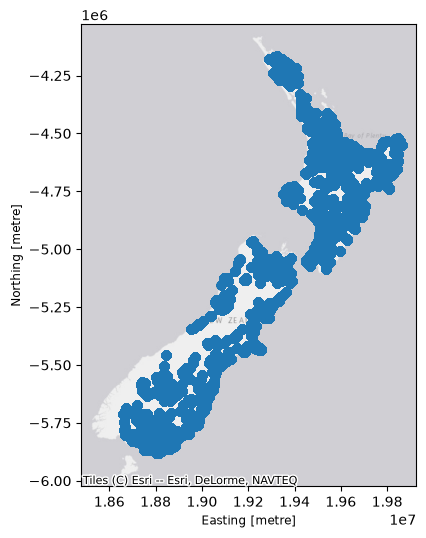

In [32]:
# Use EPSG:4326 when using this filter
filter_main_island = (gdf_water_qual.geometry.x > 0)
filter_chathams = ~(filter_main_island)

# Set boundary for the mainlands for New Zealand
minx, miny, maxx, maxy = bbox_nz.to_crs(3857).total_bounds

fig, ax = plt.subplots(1,1, figsize=(6,6))
gdf_water_qual[filter_main_island].to_crs(3857).plot(ax=ax, alpha=0.85)
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)
cx.add_basemap(ax, crs=3857, source=cx.providers.Esri.WorldGrayCanvas)


In [33]:
gdf_water_qual.columns

Index(['Region', 'Agency', 'Catchment', 'LawaSiteID', 'SiteID',
       'CouncilSiteID', 'Latitude', 'Longitude', 'WFSLanduse', 'WFSAltitude',
       'RECLandCover', 'Indicator', 'SampleDateTime', 'Timezone',
       'AgencyRawValue', 'Symbol', 'Value', 'Units', 'QCNumber',
       'QCNEMSEquivalent', 'geometry'],
      dtype='str')

In [34]:
gdf_water_qual.LawaSiteID.unique()

<ArrowStringArray>
['ecan-00192', 'ecan-00195', 'ecan-00161', 'ecan-00162', 'ecan-00103',
 'ecan-00107', 'ecan-00111', 'ecan-00176', 'ecan-10086', 'ecan-00102',
 ...
   'ew-00112',   'ew-00113',   'ew-00114',   'ew-00116',   'ew-00118',
   'ew-00087',   'ew-00097',   'ew-00100',   'ew-00106',   'ew-00115']
Length: 1138, dtype: str

In [35]:
gdf_water_qual.Indicator.unique()

<ArrowStringArray>
[          'Ammoniacal nitrogen',               'Clarity (BDISC)',
  'Dissolved inorganic nitrogen', 'Dissolved reactive phosphorus',
                        'E.coli',                            'pH',
                'Total nitrogen',       'Total oxidised nitrogen',
              'Total phosphorus',                     'Turbidity',
              'Nitrate nitrogen']
Length: 11, dtype: str

In [36]:
gdf_water_qual.SiteID.unique()

<ArrowStringArray>
[                     'Clarence River over Jacks Pass',
                    'Clarence River above river mouth',
                           'Blue Duck Creek Above SH1',
                                 'Hapuku River at SH1',
                                 'Lyell Creek u/s SH1',
                     'Warren Creek u/s Rorrisons Road',
                           'Middle Creek u/s Beach Rd',
                            'Lyell Creek at Mill Road',
                             'Lyell Creek above mouth',
                           'Kowhai River 100m u/s SH1',
 ...
           'Whangamata Stm (Kinloch) at Whangamata Rd',
             'Whanganui Stm at Lakeside Lake Taupo T8',
            'Whangape Stm at Rangiriri-Glen Murray Rd',
      'Whareroa Stm (Taupo) at Lakeside Lake Taupo T9',
                         'Whirinaki Stm at Corbett Rd',
    'Waingaro River (Pukemiro) at Ruakiwi Rd Off SH22',
 'Waitakaruru River (Hauraki Plains) at Coxhead Rd Br',
               'Waitetun

In [37]:
filter_id = (gdf_water_qual.LawaSiteID == "ecan-00192")
len(gdf_water_qual[filter_id])

555

Find mixed-type columns:

In [40]:
for col in gdf_water_qual.select_dtypes(include="object", exclude="str").columns:
    types = gdf_water_qual[col].dropna().map(type).unique()
    if len(types) > 1:
        print(col, types)

In [39]:
gdf_water_qual["LawaSiteID"] = gdf_water_qual["LawaSiteID"].str.strip()

gdf_water_qual = gdf_water_qual.sort_values(
    ["LawaSiteID", "Indicator", "Units", "SampleDateTime"]
).reset_index(drop=True)


gdf_water_qual.to_parquet(
    PROCESSED_DIR / "lawa_river_water_quality.parquet",
    compression="zstd",
    row_group_size=100_000,
    index=False,
)